<a href="https://colab.research.google.com/github/MOHAMEDAAKIFASRAR/TSA_EXP1B/blob/main/TSA_EXP1(B).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

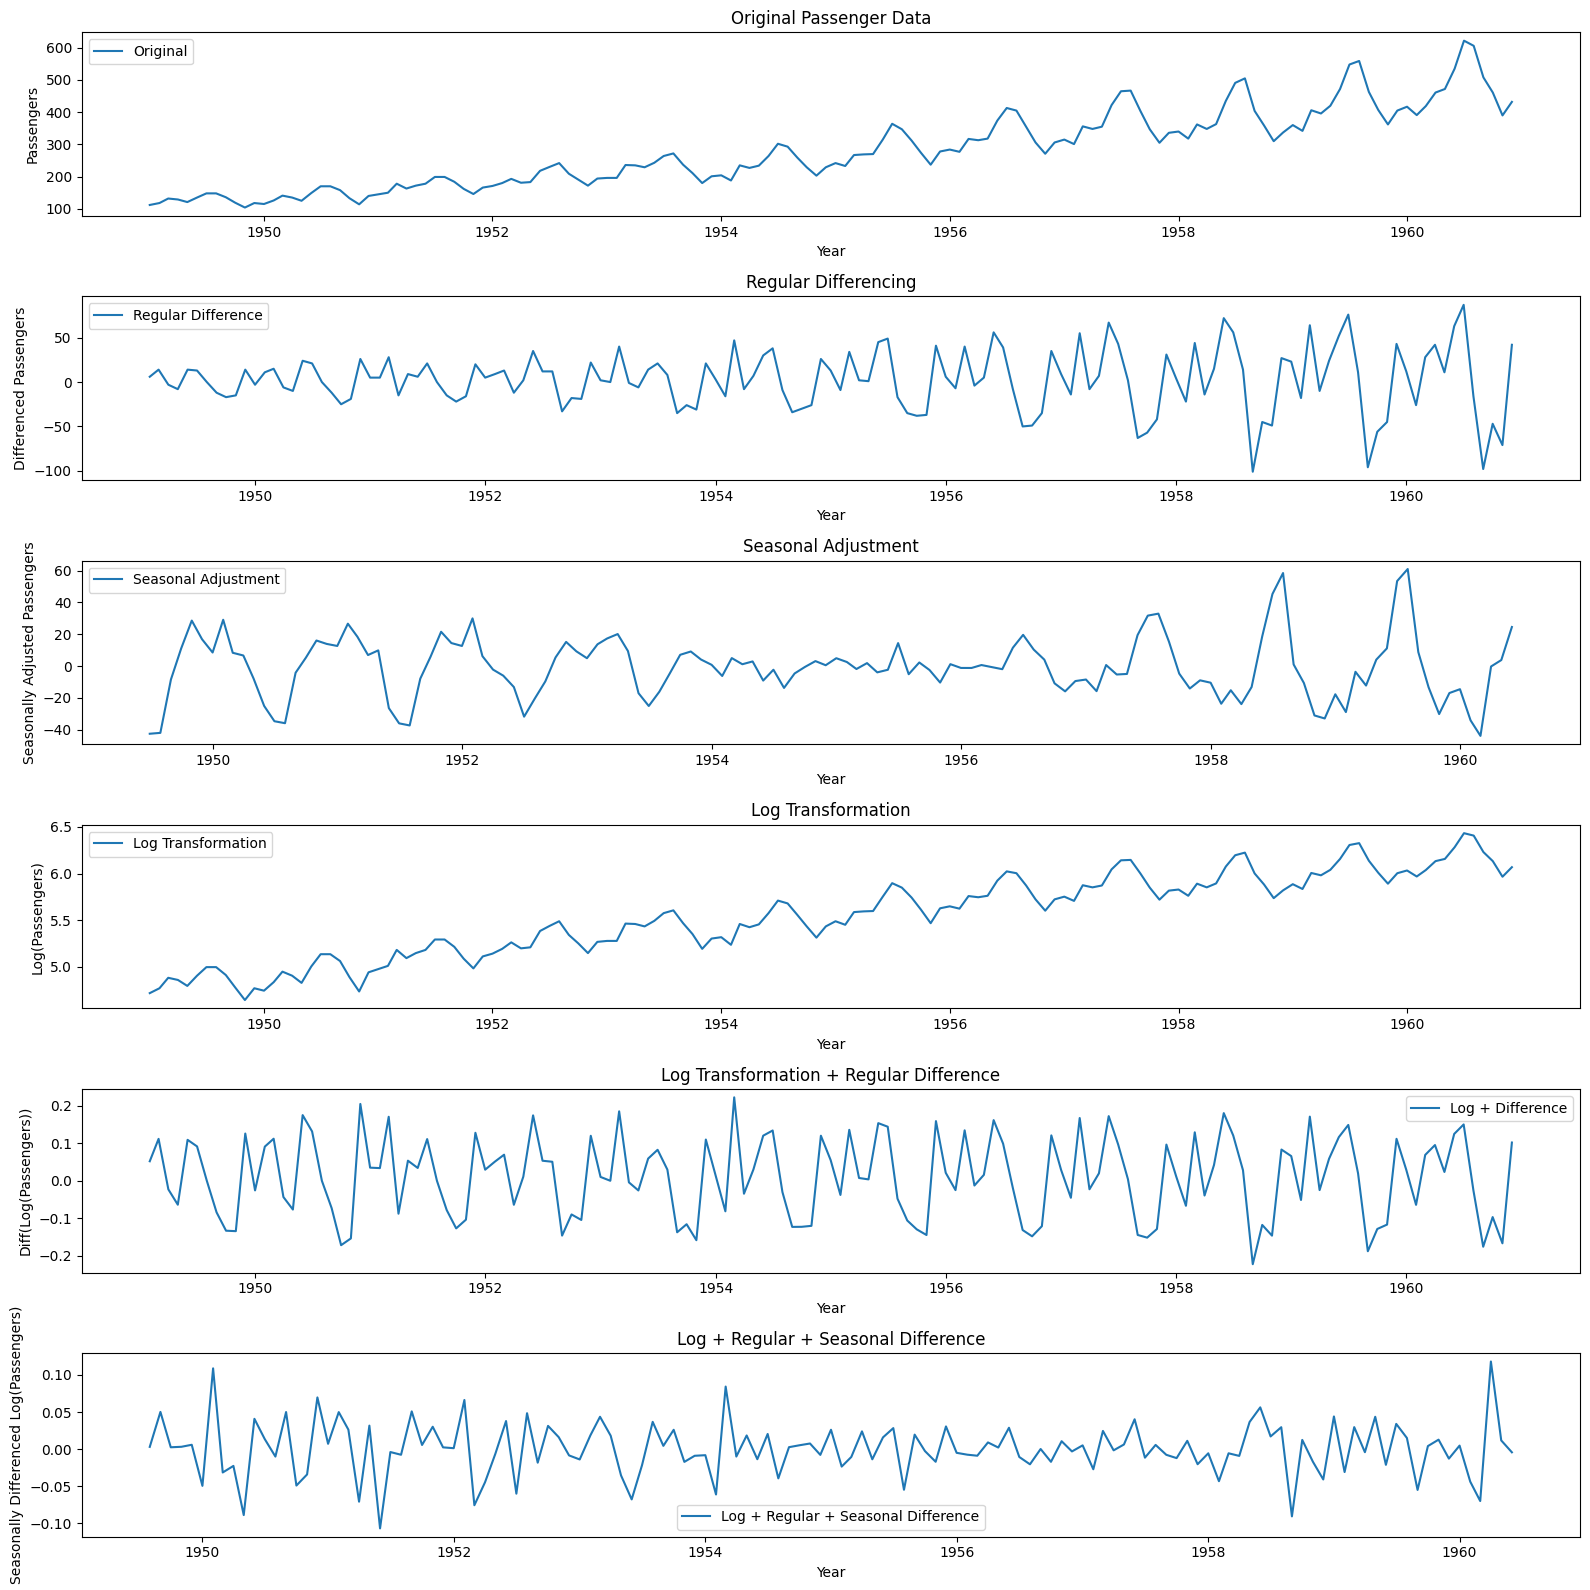

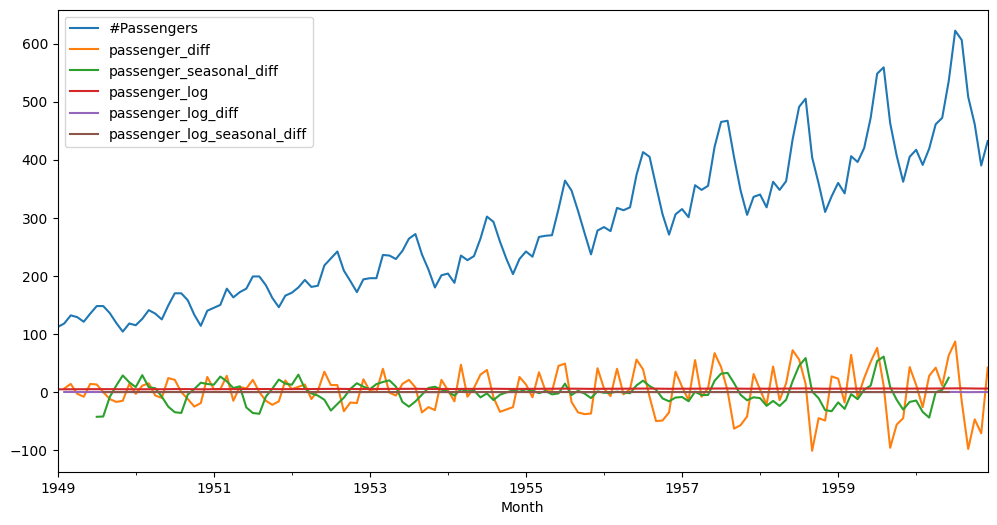

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

data = pd.read_csv("/content/AirPassengers.csv")
data['Month'] = pd.to_datetime(data['Month'])
data.set_index('Month', inplace=True)

data = data.dropna(subset=['#Passengers'])
data['passenger_diff'] = data['#Passengers'].diff()

result = seasonal_decompose(
    data['#Passengers'],
    model='additive',
    period=12
)

data['passenger_seasonal_diff'] = result.resid
data['passenger_log'] = np.log(data['#Passengers'])

# Log + Regular Difference
data['passenger_log_diff'] = (
    data['passenger_log'] -
    data['passenger_log'].shift(1)
)

# Log + Seasonal Difference
result = seasonal_decompose(
    data['passenger_log_diff'].dropna(),
    model='additive',
    period=12
)

data['passenger_log_seasonal_diff'] = result.resid
plt.figure(figsize=(16,16))

# Original Data
plt.subplot(6,1,1)
plt.plot(data['#Passengers'], label='Original')
plt.legend(loc='best')
plt.title('Original Passenger Data')
plt.xlabel('Year')
plt.ylabel('Passengers')
print()

# Regular Difference
plt.subplot(6,1,2)
plt.plot(data['passenger_diff'], label='Regular Difference')
plt.legend(loc='best')
plt.title('Regular Differencing')
plt.xlabel('Year')
plt.ylabel('Differenced Passengers')
print()

# Seasonal Adjustment
plt.subplot(6,1,3)
plt.plot(data['passenger_seasonal_diff'],
         label='Seasonal Adjustment')
plt.legend(loc='best')
plt.title('Seasonal Adjustment')
plt.xlabel('Year')
plt.ylabel('Seasonally Adjusted Passengers')
print()

# Log Transformation
plt.subplot(6,1,4)
plt.plot(data['passenger_log'],
         label='Log Transformation')
plt.legend(loc='best')
plt.title('Log Transformation')
plt.xlabel('Year')
plt.ylabel('Log(Passengers)')
print()

# Log + Difference
plt.subplot(6,1,5)
plt.plot(data['passenger_log_diff'],
         label='Log + Difference')
plt.legend(loc='best')
plt.title('Log Transformation + Regular Difference')
plt.xlabel('Year')
plt.ylabel('Diff(Log(Passengers))')
print()

# Log + Seasonal Difference
plt.subplot(6,1,6)
plt.plot(data['passenger_log_seasonal_diff'],
         label='Log + Regular + Seasonal Difference')
plt.legend(loc='best')
plt.title('Log + Regular + Seasonal Difference')
plt.xlabel('Year')
plt.ylabel('Seasonally Differenced Log(Passengers)')

plt.tight_layout()
plt.show()
print()

# Plot all transformed columns
data.plot(figsize=(12,6))
plt.show()